# PRiSM, end to end: from black box to nomogram

This notebook walks through the complete PRiSM method on the bundled synthetic
heart-transplant dataset (`htx_example`). It runs entirely in memory: no `.env`
file, no YAML config, no intermediate files on disk. Every step is a direct call
into the `prism` package, so you can see exactly what the method does and adapt
it to your own data.

## What PRiSM is

PRiSM (Partial Responses in Structured Models) converts a trained probabilistic
binary classifier for tabular data into a standalone **nomogram** that can be
audited term by term. It takes the *shape* of each nonlinear effect and
interaction from the source model, not merely which variables mattered. Two
framing points matter:

- **PRiSM replaces the source model; it does not explain it.** The nomogram is a
  standalone predictor deployed *in place of* the black box, subject to the same
  validation as any clinical tool. This is the opposite of post-hoc explainers
  (SHAP, LIME), which annotate a model that stays in production.
- **PRiSM is not knowledge distillation.** The decomposition uses only the
  model's input-output behaviour, but term *selection* is supervised by the
  **observed outcome**, not by the model's predictions.

The mathematical core is a **functional ANOVA decomposition** of the model's
log-odds $f(\mathbf{x}) = \mathrm{logit}\, P(C \mid \mathbf{x})$ into
non-overlapping component functions, truncated at second order:

$$
f(x_1, \dots, x_d) \;\approx\; \beta_0 \;+\; \sum_i \phi_i(x_i) \;+\; \sum_{i < j} \phi_{ij}(x_i, x_j)
$$

The $\phi_i$ are **univariate main effects** and the $\phi_{ij}$ are **bivariate
interactions** (together, PRiSM's "partial responses"). Truncation at second
order is the fundamental interpretability/fidelity trade-off: any genuinely
higher-order structure the model learned is given up in exchange for a
representation a human can read and sum by hand.

The pipeline has two phases:

1. **Phase I - decomposition and selection.** Decompose the trained black box
   into partial responses; a LASSO regression against the observed outcome
   selects the predictively informative terms and weights them, giving a
   **baseline nomogram**. This is already a usable end product.
2. **Phase II - PRN refinement (optional).** The selected effects define the
   architecture of a **Partial Response Network** (PRN): a structured network
   re-trained on the outcome, in which higher-order interactions are impossible
   by construction. Re-decomposing the PRN and running a second LASSO gives a
   **PRN-refined nomogram**.

**Runtime:** about 5 minutes on a GPU and 10-20 minutes on CPU with the
default `lebesgue` decomposition. For a fast first pass, set
`method = "dirac"` in the setup cell below (about a minute; see the Phase I
notes for what changes).

In [67]:
import os

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # Apple Silicon fallback

from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from prism.config_loader import load_label_file
from prism.data import load_htx_example_splits
from prism.device_tools import cleanup_gpu_memory, get_device, get_num_cpu_workers
from prism.feature_labels import FeatureLabelManager
from prism.lasso import LassoRegression
from prism.maskedmlp import build_prn_from_lasso, train_mlp
from prism.metrics import compare_model_performance, evaluate_model_performance
from prism.nomogram_plot import display_nomograms_side_by_side, nomogram
from prism.notebook_utils import get_term_counts, get_training_history, plot_training_history
from prism.partial_responses import partial_responses
from prism.partial_responses.utils import stable_logit

random_seed = 257
np.random.seed(random_seed)
torch.manual_seed(random_seed)

device = get_device()
print(f"Using device: {device}")

# 'lebesgue' is the default method: effects are averaged over the empirical
# data distribution, preserving real-world correlations. 'dirac' isolates each
# effect against the median reference instead: much faster, but it ignores the
# correlation structure. They are two different decompositions, not two
# approximations of one another.
method = "lebesgue"

Using device: cpu


## 1. Load and preprocess the data

`htx_example` is a fully synthetic 5,000-row heart-transplant cohort built to
the schema of UNOS heart-transplant registry data: 1-year mortality as the
outcome, a mix of continuous and categorical predictors, and missing values. Its
predefined train/test/validation split is temporal (2000 to 2016, 2017 to 2019, and
2020 to 2022). (PRiSM uses "test" for tuning-time decisions and "validation" for
final held-out evaluation.)

One call handles the whole preprocessing pipeline: binary target encoding,
categorical detection, one-hot encoding with reference categories, imputation,
splitting, and scaler fitting. The returned bundle keeps together the three
things the decomposition will need as a unit: the fitted **scaler**, the
**one-hot group manager**, and the **feature names**. Encoded categoricals are
treated as *one variable* at every stage of PRiSM, and the group manager is
what makes that possible.

In [68]:
data = load_htx_example_splits(random_seed=random_seed)

print(f"\nTrain: {data.X_train.shape}, test: {data.X_test.shape}, val: {data.X_val.shape}")
print(
    f"Outcome prevalence - train: {data.y_train.mean():.3f}, "
    f"test: {data.y_test.mean():.3f}, val: {data.y_val.mean():.3f}"
)
print(
    f"{len(data.feature_names)} one-hot encoded features collapse to "
    f"{len(data.collapsed_feature_names)} variables"
)
print(f"One-hot groups: {list(data.group_manager.groups_dict.keys())}")

Enforcing binary encoding for target variable: MORTALITY_365D
Original unique values: ['No', 'Yes']
Mapping arbitrary binary values: 'No' -> 0, 'Yes' -> 1
[OK] Target variable successfully encoded as binary: [np.int64(0), np.int64(1)]
Data type: int64
Distribution: {0: np.int64(4514), 1: np.int64(486)}
Found 12 total categorical columns:
  7 binary columns
  5 multi-category columns

Binary categorical columns:
  DAT_VENTILATOR_TRR: ['No', 'Yes'] - {'No': 4905, 'Yes': 95}
  DAT_DIAL_AFTER_LIST: ['No', 'Yes'] - {'No': 4795, 'Yes': 205}
  DAT_TRANSFUSIONS: ['No', 'Yes'] - {'No': 3934, 'Yes': 1066}
  DAT_INFECT_IV_DRUG_TRR: ['No', 'Yes'] - {'No': 4453, 'Yes': 547}
  DAT_ECMO_TRR: ['No', 'Yes'] - {'No': 4920, 'Yes': 80}
  DAT_IMPL_DEFIBRIL: ['No', 'Yes'] - {'Yes': 3374, 'No': 1626}
  DAT_ALCOHOL_HEAVY_DON: ['No', 'Yes'] - {'No': 4092, 'Yes': 908}

Multi-category columns:
  DAT_VAD_DEVICE_TY_TRR: 5 categories ['BiVAD', 'LVAD', 'LVAD/RVAD/TAH Unspecified', 'NONE', 'RVAD'] - {'NONE': 3141, 'L

In [69]:
# Scale features and move to the compute device (one-hot columns stay 0/1)
X_tr = data.scaler.to_tensor(data.X_train, device=device)
X_te = data.scaler.to_tensor(data.X_test, device=device)
X_va = data.scaler.to_tensor(data.X_val, device=device)

# Human-readable variable labels for plots (falls back to raw column names)
variable_labels = load_label_file(["htx_example_variable_labels.csv"])
if variable_labels is None:
    variable_labels = {name: name for name in data.feature_names}
label_manager = FeatureLabelManager(variable_labels)

# Collapsed-space labels: one name per variable, categoricals as a single entry
lasso_feature_names = [label_manager.get_label(n) for n in data.collapsed_feature_names]

## 2. Train the black-box model

PRiSM is model-agnostic: it only ever queries the trained model through
`predict_proba`, never its internals. Any probabilistic classifier works (the
repo pipeline also supports XGBoost, random forests, logistic regression, and a
fixed published risk score). Here we train an MLP with hyperparameters tuned
for this synthetic dataset.

Epoch 0, Train Loss 0.643973, Test Loss 0.565047, Train AUROC 0.5235, Test AUROC 0.5251
Epoch 10, Train Loss 0.351599, Test Loss 0.330413, Train AUROC 0.4902, Test AUROC 0.5391
Epoch 20, Train Loss 0.334965, Test Loss 0.322124, Train AUROC 0.5494, Test AUROC 0.5606
Epoch 30, Train Loss 0.325964, Test Loss 0.318504, Train AUROC 0.5942, Test AUROC 0.5792
Epoch 40, Train Loss 0.319929, Test Loss 0.317741, Train AUROC 0.6198, Test AUROC 0.5820
Epoch 50, Train Loss 0.314922, Test Loss 0.314721, Train AUROC 0.6403, Test AUROC 0.5949
Epoch 60, Train Loss 0.310891, Test Loss 0.313795, Train AUROC 0.6579, Test AUROC 0.6018
Epoch 70, Train Loss 0.307149, Test Loss 0.313065, Train AUROC 0.6761, Test AUROC 0.6082
Epoch 80, Train Loss 0.304057, Test Loss 0.312600, Train AUROC 0.6909, Test AUROC 0.6128
Epoch 90, Train Loss 0.301561, Test Loss 0.309092, Train AUROC 0.7032, Test AUROC 0.6314
Epoch 100, Train Loss 0.299112, Test Loss 0.308586, Train AUROC 0.7133, Test AUROC 0.6362
Epoch 110, Train Loss

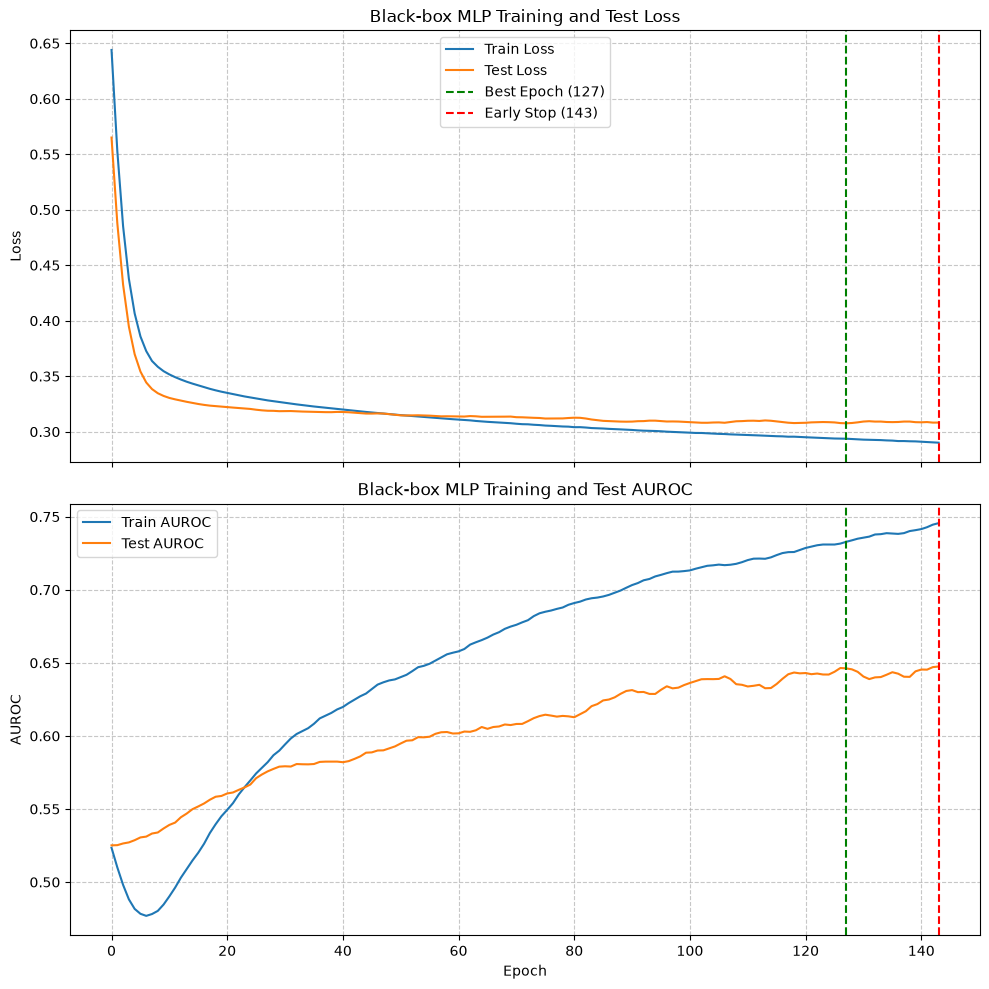

True

In [70]:
blackbox = train_mlp(
    X_tr,
    data.y_train,
    X_te,
    data.y_test,
    n_hidden=36,
    lr=0.0014,
    weight_decay=6e-5,
    tolerance=0.0001,
    patience=16,
    max_iter=4000,
    batch_size=512,
    scale_lr=False,
    device=str(device),
    seed=random_seed,
    plot_loss=False,
)
plot_training_history(get_training_history(blackbox), title_prefix="Black-box MLP")

C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: Black box (MLP) - test data: Skipped confidence intervals for 1 bin(s) due to insufficient samples (threshold: 5). Bin indices: [4]. These bins had the following sample counts: [0.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:210: UserWarning: Black box (MLP) - test data: 5 point(s) omitted: insufficient samples in probability range(s). Points omitted for probability range(s) [4]: no predictions in these ranges
  warnings.warn(



---- Model Performance Metrics Black box (MLP) - test data ----
Threshold (prevalence) set to: 0.100
AUROC:		0.647 (95% CI: 0.593-0.717) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.661 (Proportion of correct predictions)
Precision:	0.159 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.583 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.249 (Harmonic mean of precision and recall)
--------------------------------------------


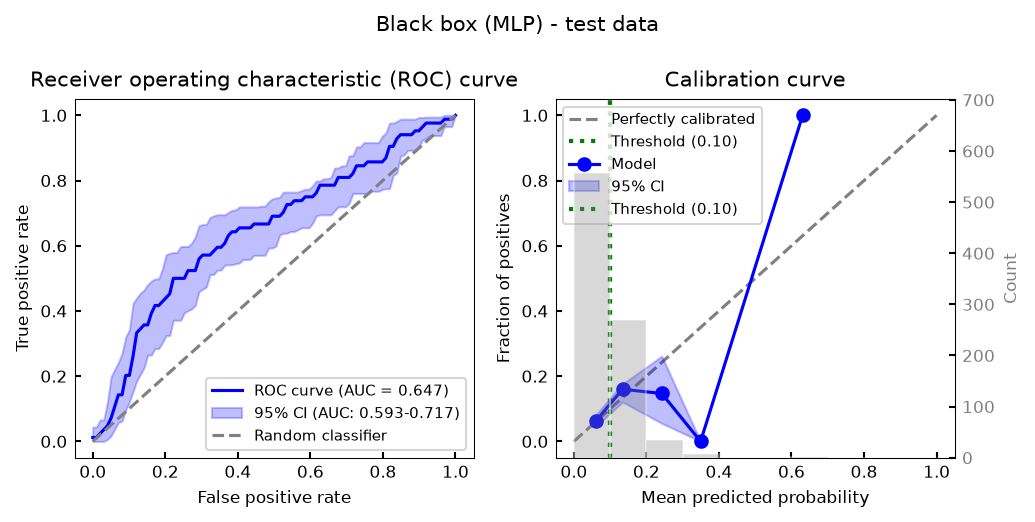

In [71]:
y_pred_test_blackbox = blackbox.predict_proba(X_te, device=device)
results_blackbox_test = evaluate_model_performance(
    data.y_test, y_pred_test_blackbox, data.y_train, title="Black box (MLP) - test data"
)

## 3. Phase I: decompose the black box into partial responses

The decomposition rewrites the model's log-odds as a sum of baseline-relative
component functions. With the **Lebesgue** method, the main effect of variable
$i$ is an interventional average over the empirical distribution of the other
variables:

$$
\phi_i(x_i) \;=\; \mathbb{E}_{\mathbf{X}}\!\left[ f(x_i, \mathbf{X}_{-i}) \right] \;-\; \mathbb{E}_{\mathbf{X}}\!\left[ f(\mathbf{X}) \right]
$$

(fix column $i$ to $x_i$ across every row of the training data, average the
model's log-odds, and subtract the global average). The **Dirac** method instead
fixes the other variables at a single reference point, the median for continuous
variables and the reference category for encoded categoricals: cheaper, but
blind to correlations. A bivariate interaction is what remains of a joint effect after
its main effects are removed:

$$
\phi_{ij}(x_i, x_j) \;=\; \left( \text{joint effect of } x_i, x_j \right) \;-\; \phi_i(x_i) \;-\; \phi_j(x_j)
$$

so for a model with no true $i \times j$ interaction, $\phi_{ij} \approx 0$.
Three things to keep in mind:

- **Everything lives on the log-odds scale.** Effects are only additive there;
  probabilities appear at the very end via the logistic transform.
- **The decomposition never sees the outcome**, only the model's input-output
  behaviour. Outcome labels enter at the selection step (next section).
- **A categorical variable moves as one unit.** Fixing it means setting its
  whole one-hot group to a valid category pattern, which is why the group
  manager, scaler and feature names travel together into the calculator.

In [72]:
pr_params = {
    "x_train": X_tr,
    "method": method,
    "device": device,
    "batch_size": 128,
    "group_manager": data.group_manager,
    "feature_names": data.feature_names,
    "scaler": data.scaler,
}

pr_train = partial_responses(X_tr, blackbox, **pr_params)
pr_test = partial_responses(X_te, blackbox, **pr_params)

n_vars = len(data.collapsed_feature_names)
print(f"Partial response matrix: {pr_train.shape}")
print(
    f"  = {n_vars} univariate main effects + "
    f"{n_vars * (n_vars - 1) // 2} bivariate interactions, per sample"
)
cleanup_gpu_memory(device)

Partial response matrix: torch.Size([3166, 253])
  = 22 univariate main effects + 231 bivariate interactions, per sample


### A single main effect

Each univariate column of the matrix is one $\phi_i$ evaluated at every training
sample. Plotting it against the raw variable shows the response curve the model
learned (here, recipient age). This curve (times its LASSO weight) is exactly
what will appear as the age scale of the final nomogram.

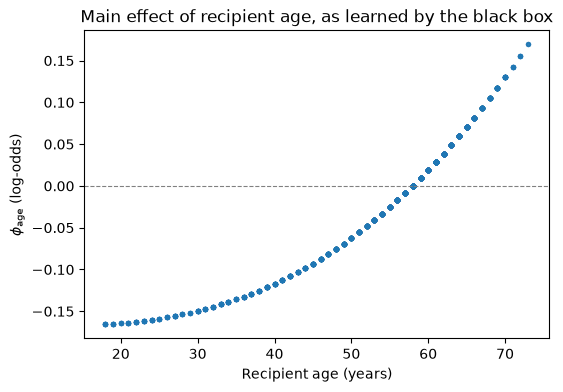

In [73]:
age_idx = data.collapsed_feature_names.index("DAT_AGE")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(data.X_train["DAT_AGE"], pr_train[:, age_idx], s=8, alpha=0.4)
ax.axhline(0.0, color="gray", lw=0.8, ls="--")
ax.set_xlabel("Recipient age (years)")
ax.set_ylabel(r"$\phi_{\mathrm{age}}$ (log-odds)")
ax.set_title("Main effect of recipient age, as learned by the black box")
plt.show()

### A single interaction

The remaining columns are the $\phi_{ij}$, one per variable pair: what is left of
a pair's joint effect once both main effects have been removed. Plotted over the
two variables it belongs to, with the interaction on the color scale, it shows
what the model learned jointly about them, here recipient age and creatinine
clearance. Where an interaction is flat, the model learned nothing about that
pair beyond its two main effects.

None of the interactions survives the LASSO sweep in the next section: selection
goes by contribution to predicting the outcome, and on this data none of them
earns its penalty.

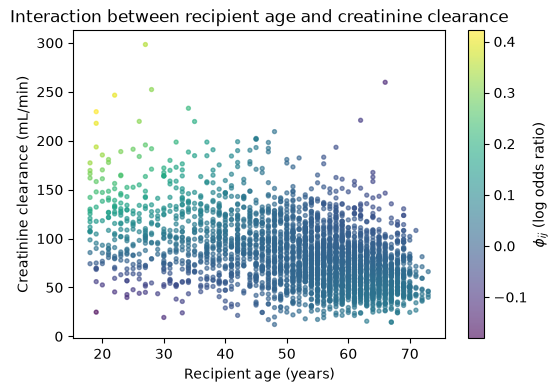

In [74]:
# Bivariate columns follow the univariate ones, in itertools.combinations order
i = data.collapsed_feature_names.index("DAT_AGE")
j = data.collapsed_feature_names.index("DAT_CREATININE_CLEARANCE")
pair_idx = n_vars + list(combinations(range(n_vars), 2)).index((min(i, j), max(i, j)))

fig, ax = plt.subplots(figsize=(6, 4))
points = ax.scatter(
    data.X_train["DAT_AGE"], data.X_train["DAT_CREATININE_CLEARANCE"],
    c=pr_train[:, pair_idx].numpy(), cmap="viridis", s=8, alpha=0.6,
)
fig.colorbar(points, ax=ax, label=r"$\phi_{ij}$ (log odds ratio)")
ax.set_xlabel("Recipient age (years)")
ax.set_ylabel("Creatinine clearance (mL/min)")
ax.set_title("Interaction between recipient age and creatinine clearance")
plt.show()

### The reconstruction identity

Summing *all* partial responses plus the baseline should reproduce the model's
log-odds: exactly for a model with no higher-order interactions, and up to the
second-order truncation otherwise. This is the single most diagnostic check of a
decomposition: the scatter below hugging the diagonal is the truncation working;
any vertical spread *is* the higher-order structure the nomogram gives up.
Correlation on its own would miss a scale or offset error, so the residual is
reported with it. On a source model with no higher-order structure (e.g., a logistic
regression) the residual is zero to numerical precision.

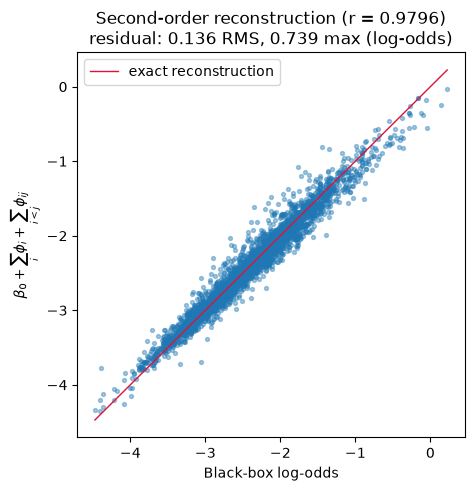

In [75]:
logit_bb = stable_logit(blackbox.predict_proba(X_tr, device=device)).squeeze().cpu()
if method == "lebesgue":
    baseline = logit_bb.mean().item()  # Lebesgue baseline: E[f(X)] over the training data
else:
    zero_input = torch.zeros(1, X_tr.shape[1], device=device)
    baseline = stable_logit(blackbox.predict_proba(zero_input)).item()  # Dirac: f at reference

reconstruction = pr_train.sum(dim=1) + baseline
corr = np.corrcoef(reconstruction.numpy(), logit_bb.numpy())[0, 1]

residual = (reconstruction - logit_bb).numpy()
rms_residual = float(np.sqrt(np.mean(residual**2)))
max_residual = float(np.max(np.abs(residual)))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(logit_bb, reconstruction, s=8, alpha=0.4)
lims = [logit_bb.min().item(), logit_bb.max().item()]
ax.plot(lims, lims, color="crimson", lw=1, label="exact reconstruction")
ax.set_xlabel("Black-box log-odds")
ax.set_ylabel(r"$\beta_0 + \sum_i \phi_i + \sum_{i<j} \phi_{ij}$")
ax.set_title(
    f"Second-order reconstruction (r = {corr:.4f})\n"
    f"residual: {rms_residual:.3f} RMS, {max_residual:.3f} max (log-odds)"
)
ax.legend()
plt.show()

## 4. Phase I: LASSO selection

This is where the observed outcome enters. An $L_1$-penalized logistic
regression is fitted with the partial responses as predictors and the outcome as
the target, sweeping the regularization strength $\lambda$. The partial-response
*shapes* stay fixed as derived from the model; the outcome decides **which**
terms are kept and with what weight $\beta_k$. This is why the nomogram is a
translation of the model, not a distilled copy of its predictions.

Details that matter:

- $\lambda$ is the real complexity control. We pick the sparsest $\lambda$ whose
  tuning-set AUROC stays within 99.8% of the sweep's maximum (the "baseline"
  criterion).
- Coefficients with $|\beta| \le 0.1$ are treated as noise LASSO did not fully
  shrink to zero. The 0.1 threshold is fixed.
- A categorical variable occupies a single column (its per-sample category
  effect), so LASSO keeps or drops the *variable*; if kept, all its category
  effects are scaled by the one shared $\beta$.

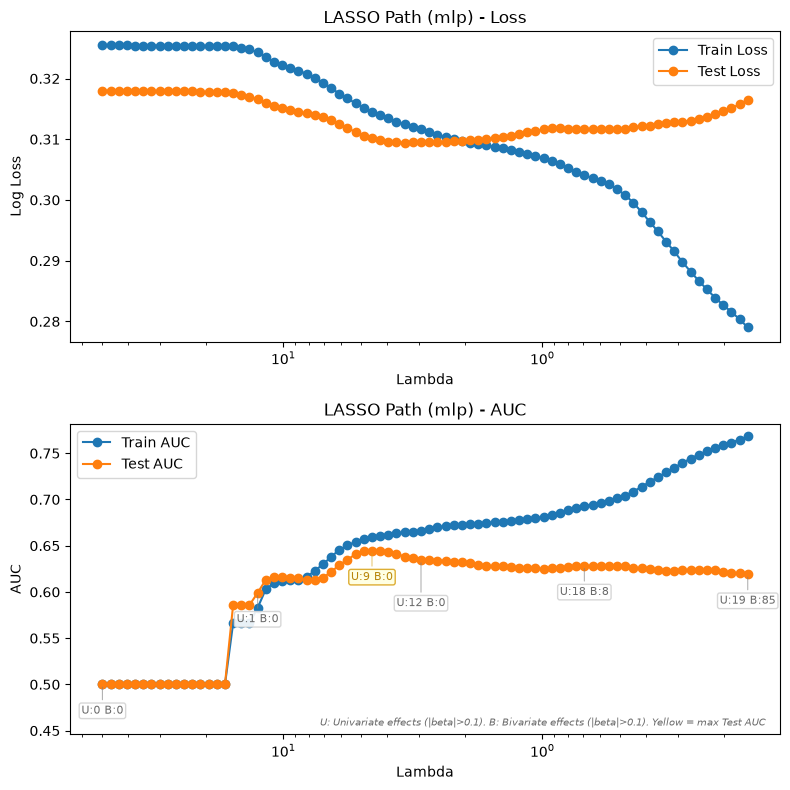

                       LASSO Regression Results (mlp)                       
╭───────┬────────┬────────┬────────┬────────┬────────┬──────────┬──────────╮
│       │        │  Train │   Test │  Train │   Test │    Univ. │     Biv. │
│ Index │ Lambda │    AUC │    AUC │   Loss │   Loss │ beta>0.1 │ beta>0.1 │
├───────┼────────┼────────┼────────┼────────┼────────┼──────────┼──────────┤
│     0 │     50 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     1 │   46.5 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     2 │  43.24 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     3 │  40.21 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     4 │   37.4 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     5 │  34.78 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     6 │  32.34 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3179 │        0 │        0 │
│     7 │  30.08 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3179 │        0 │        0 │
│     8 │  27.97 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3179 │        0 │        0 │
│     9 │  26.01 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3179 │        0 │        0 │
│    10 │  24.19 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3179 │        0 │        0 │
│    11 │  22.49 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3179 │        0 │        0 │
│    12 │  20.92 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    13 │  19.45 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    14 │  18.09 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    15 │  16.82 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3178 │        0 │        0 │
│    16 │  15.65 │ 0.5662 │ 0.5859 │ 0.3253 │ 0.3176 │        0 │        0 │
│    17 │  14.55 │ 0.5662 │ 0.5859 │ 0.3250 │ 0.3173 │        0 │        0 │
│    18 │  13.53 │ 0.5662 │ 0.5859 │ 0.3248 │ 0.3170 │        1 │        0 │
│    19 │  12.58 │ 0.5828 │ 0.5990 │ 0.3243 │ 0.3166 │        1 │        0 │
│    20 │   11.7 │ 0.6030 │ 0.6132 │ 0.3235 │ 0.3160 │        2 │        0 │
│    21 │  10.88 │ 0.6095 │ 0.6160 │ 0.3228 │ 0.3155 │        3 │        0 │
│    22 │  10.12 │ 0.6119 │ 0.6162 │ 0.3222 │ 0.3151 │        3 │        0 │
│    23 │  9.411 │ 0.6129 │ 0.6150 │ 0.3217 │ 0.3147 │        3 │        0 │
│    24 │  8.752 │ 0.6133 │ 0.6146 │ 0.3213 │ 0.3145 │        3 │        0 │
│    25 │  8.139 │ 0.6158 │ 0.6133 │ 0.3208 │ 0.3143 │        3 │        0 │
│    26 │  7.569 │ 0.6231 │ 0.6127 │ 0.3201 │ 0.3140 │        4 │        0 │
│    27 │  7.038 │ 0.6298 │ 0.6153 │ 0.3193 │ 0.3137 │        5 │        0 │
│    28 │  6.545 │ 0.6381 │ 0.6218 │ 0.3184 │ 0.3131 │        6 │        0 │
│    29 │  6.087 │ 0.6455 │ 0.6291 │ 0.3175 │ 0.3125 │        8 │        0 │
│    30 │  5.661 │ 0.6503 │ 0.6349 │ 0.3167 │ 0.3119 │        8 │        0 │
│    31 │  5.264 │ 0.6544 │ 0.6409 │ 0.3159 │ 0.3112 │        8 │        0 │
│    32 │  4.895 │ 0.6571 │ 0.6439 │ 0.3152 │ 0.3106 │        9 │        0 │
│  * 33 │  4.553 │ 0.6592 │ 0.6445 │ 0.3146 │ 0.3101 │        9 │        0 │
│    34 │  4.234 │ 0.6603 │ 0.6444 │ 0.3140 │ 0.3098 │       10 │        0 │
│    35 │  3.937 │ 0.6614 │ 0.6432 │ 0.3135 │ 0.3095 │       10 │        0 │
│    36 │  3.661 │ 0.6632 │ 0.6412 │ 0.3129 │ 0.3095 │       10 │        0 │
│    37 │  3.405 │ 0.6644 │ 0.6383 │ 0.3124 │ 0.3094 │       12 │        0 │
│    38 │  3.166 │ 0.6653 │ 0.6363 │ 0.3120 │ 0.3095 │       12 │        0 │
│    39 │  2.945 │ 0.6664 │ 0.6344 │ 0.3116 │ 0.3095 │       12 │        0 │
│    40 │  2.738 │ 0.6681 │ 0.6348 │ 0.3112 │ 0.3095 │       13 │        0 │
│    41 │  2.547 │ 0.6699 │ 0.6340 │ 0.3107 │ 0.3095 │       15 │        0 │
│    42 │  2.368 │ 0.6711 │ 0.6337 │ 0.3103 │ 0.3096 │       15 │        0 │
│    43 │  2.202 │ 0.6720 │ 0.6329 │ 0.3100 │ 0.3096 │       15 │        0 │
│    44 │  2.048 │ 0.6728 │ 0.6324 │ 0.3097 │ 0.3097 │       15 │        0 │
│    45 │  1.905 │ 0.6734 │ 0.6309 │ 0.3095 │ 0.3098 │       15 │        0 │
│    46 │  1.771 │ 0.6739 │ 0.6295 │ 0.3092 │ 0.3100 │       15 │        

Logging is configured but no file handlers were found.


In [76]:
lasso_blackbox = LassoRegression(
    nlambda=150,
    min_lambda=0.001,
    max_lambda=50,
    max_features=100,
    max_workers=get_num_cpu_workers(),
    seed=random_seed,
    base_model_name="mlp",
)
lasso_results, _ = lasso_blackbox.fit(
    pr_train, pr_test, data.y_train, data.y_test, feature_names=lasso_feature_names
)

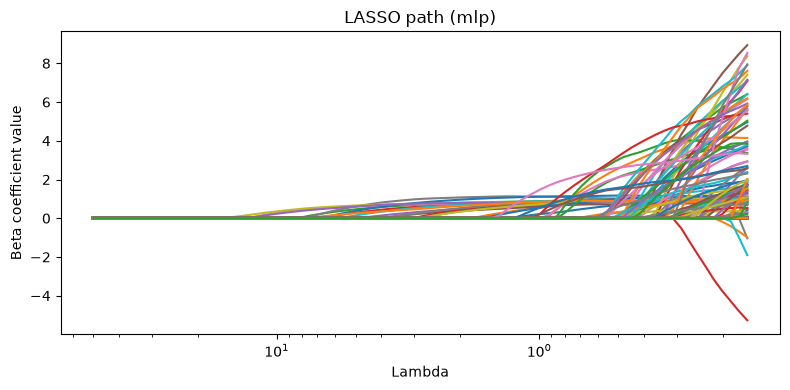

╭──────────────────────────────────────────────── Model Selection ────────────────────────────────────────────────╮
│ Lambda Selection Strategy: Target Ratio 99.8% of Max AUC                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

         Selected Lambda Results         
╭──────────────────────────────┬────────╮
│                       Metric │ Value  │
├──────────────────────────────┼────────┤
│                 Lambda Index │ 32     │
│                 Lambda Value │ 4.8955 │
│                     Test AUC │ 0.6439 │
│                    Train AUC │ 0.6571 │
│               Total Features │ 9      │
│          Univariate Features │ 9      │
│           Bivariate Features │ 0      │
├──────────────────────────────┼────────┤
│         Maximum Possible AUC │ 0.6445 │
│     Maximum AUC Lambda Index │ 33     │
│       Percent of Maximum AUC │ 99.9%  │
├──────────────────────────────┼────────┤
│       Max AUC Model Features │ 9      │
│            Feature Reduction │ 0.0%   │
│ Univariate Feature Reduction │ 0.0%   │
│  Bivariate Feature Reduction │ N/A    │
╰──────────────────────────────┴────────╯

                   Selected Features (|beta| > 0.1)                   
╭────────────────────┬────────────────────────────────┬──────────────╮
│ Coefficient (beta) │ Feature                        │     Type     │
├────────────────────┼────────────────────────────────┼──────────────┤
│             0.6619 │ Creatinine Clearance (mL/min)  │  Univariate  │
│             0.6307 │ Prior Blood Transfusions       │  Univariate  │
│             0.6155 │ Dialysis Dependence            │  Univariate  │
│             0.6139 │ Body-Mass Index (kg/m2)        │  Univariate  │
│             0.4737 │ HCV Seropositivity             │  Univariate  │
│             0.4027 │ Donor Age (years)              │  Univariate  │
│             0.3052 │ Primary Cause of Heart Failure │  Univariate  │
│             0.2677 │ Height (cm)                    │  Univariate  │
│             0.1661 │ Total Bilirubin (mg/dL)        │  Univariate  │
├────────────────────┼────────────────────────────────┼──────────────┤
│           Total: 9 │ Univariate: 9                  │ Bivariate: 0 │
╰────────────────────┴────────────────────────────────┴──────────────╯

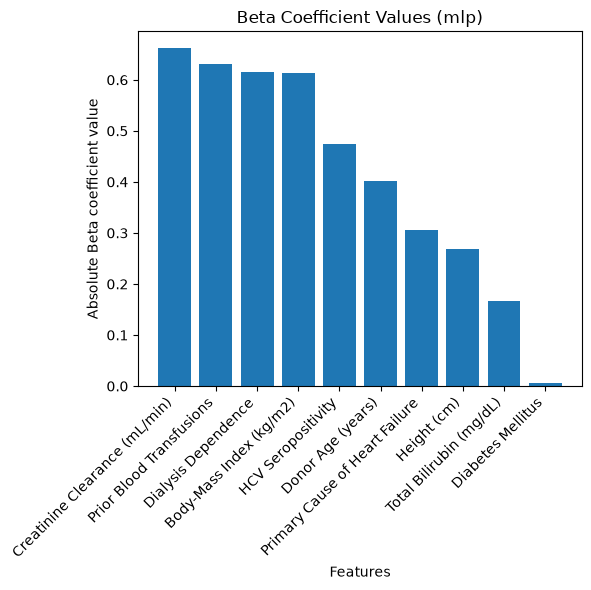

In [77]:
lasso_results.plot_lambda_path()
lasso_results.select_lambda_max_test_auc(target_ratio=0.998)
lasso_results.plot_beta_values()

Logistic regression model for Lambda index 32 (4.895) selected. |beta| > 0.1 kept.

---- Model Performance Metrics Baseline nomogram - test data ----
Threshold (prevalence) set to: 0.100
AUROC:		0.644 (95% CI: 0.603-0.714) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.605 (Proportion of correct predictions)
Precision:	0.145 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.631 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.236 (Harmonic mean of precision and recall)
--------------------------------------------


C:\Users\user\PRiSM\prism\metrics.py:210: UserWarning: Baseline nomogram - test data: 7 point(s) omitted: insufficient samples in probability range(s)
  warnings.warn(


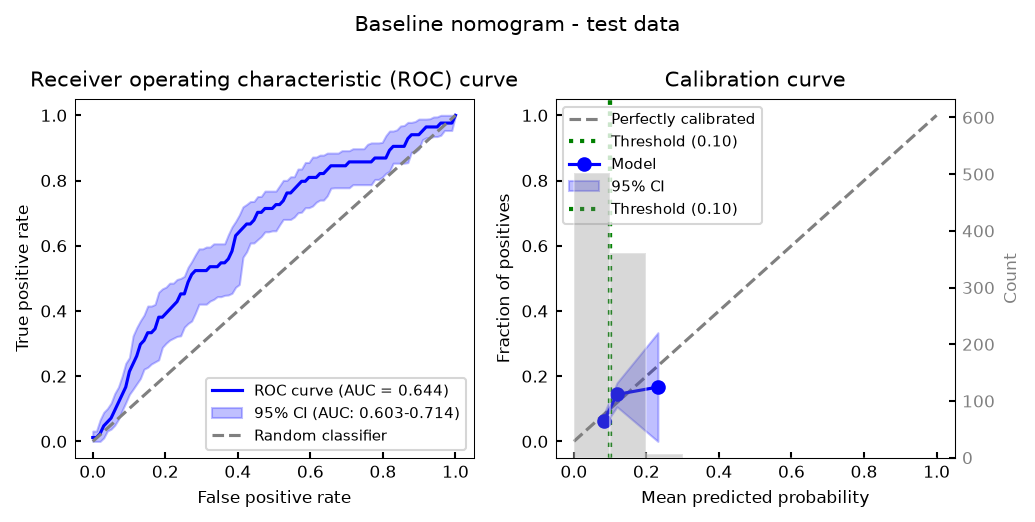

Selected 9 terms (9 main effects, 0 interactions)


In [78]:
# The selected terms + weights already form a working predictor
blackbox_nomogram = lasso_results.get_selected_model()
y_pred_test_bb_nomogram = blackbox_nomogram.predict_proba(pr_test)[:, 1]
results_bb_nomogram_test = evaluate_model_performance(
    data.y_test, y_pred_test_bb_nomogram, data.y_train, title="Baseline nomogram - test data"
)
counts = get_term_counts(lasso_results)
print(
    f"Selected {counts['n_total']} terms "
    f"({counts['n_univ']} main effects, {counts['n_biv']} interactions)"
)

## 5. The baseline nomogram

The deployed predictor is purely additive on the log-odds scale:

$$
\mathrm{logit} \;=\; \beta_0 + \sum_k \beta_k\, \phi_k(\mathbf{x}), \qquad P = \frac{1}{1 + e^{-\mathrm{logit}}}
$$

Each selected effect becomes one scale of the nomogram, with the convention
**1 point = 0.1 log-odds**. To score a patient by hand: read the points off each
scale at the patient's values, sum them, and convert the total to a probability
via the conversion line. Nothing is re-computed at prediction time: the curves
below *are* the model.

On this synthetic dataset the baseline selection keeps main effects only, so the
nomogram has one scale per variable and no interaction surfaces. On larger
datasets interactions routinely survive.

Logistic regression model for Lambda index 32 (4.895) selected. |beta| > 0.1 kept.


C:\Users\user\PRiSM\prism\plotting\renderer.py:1182: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


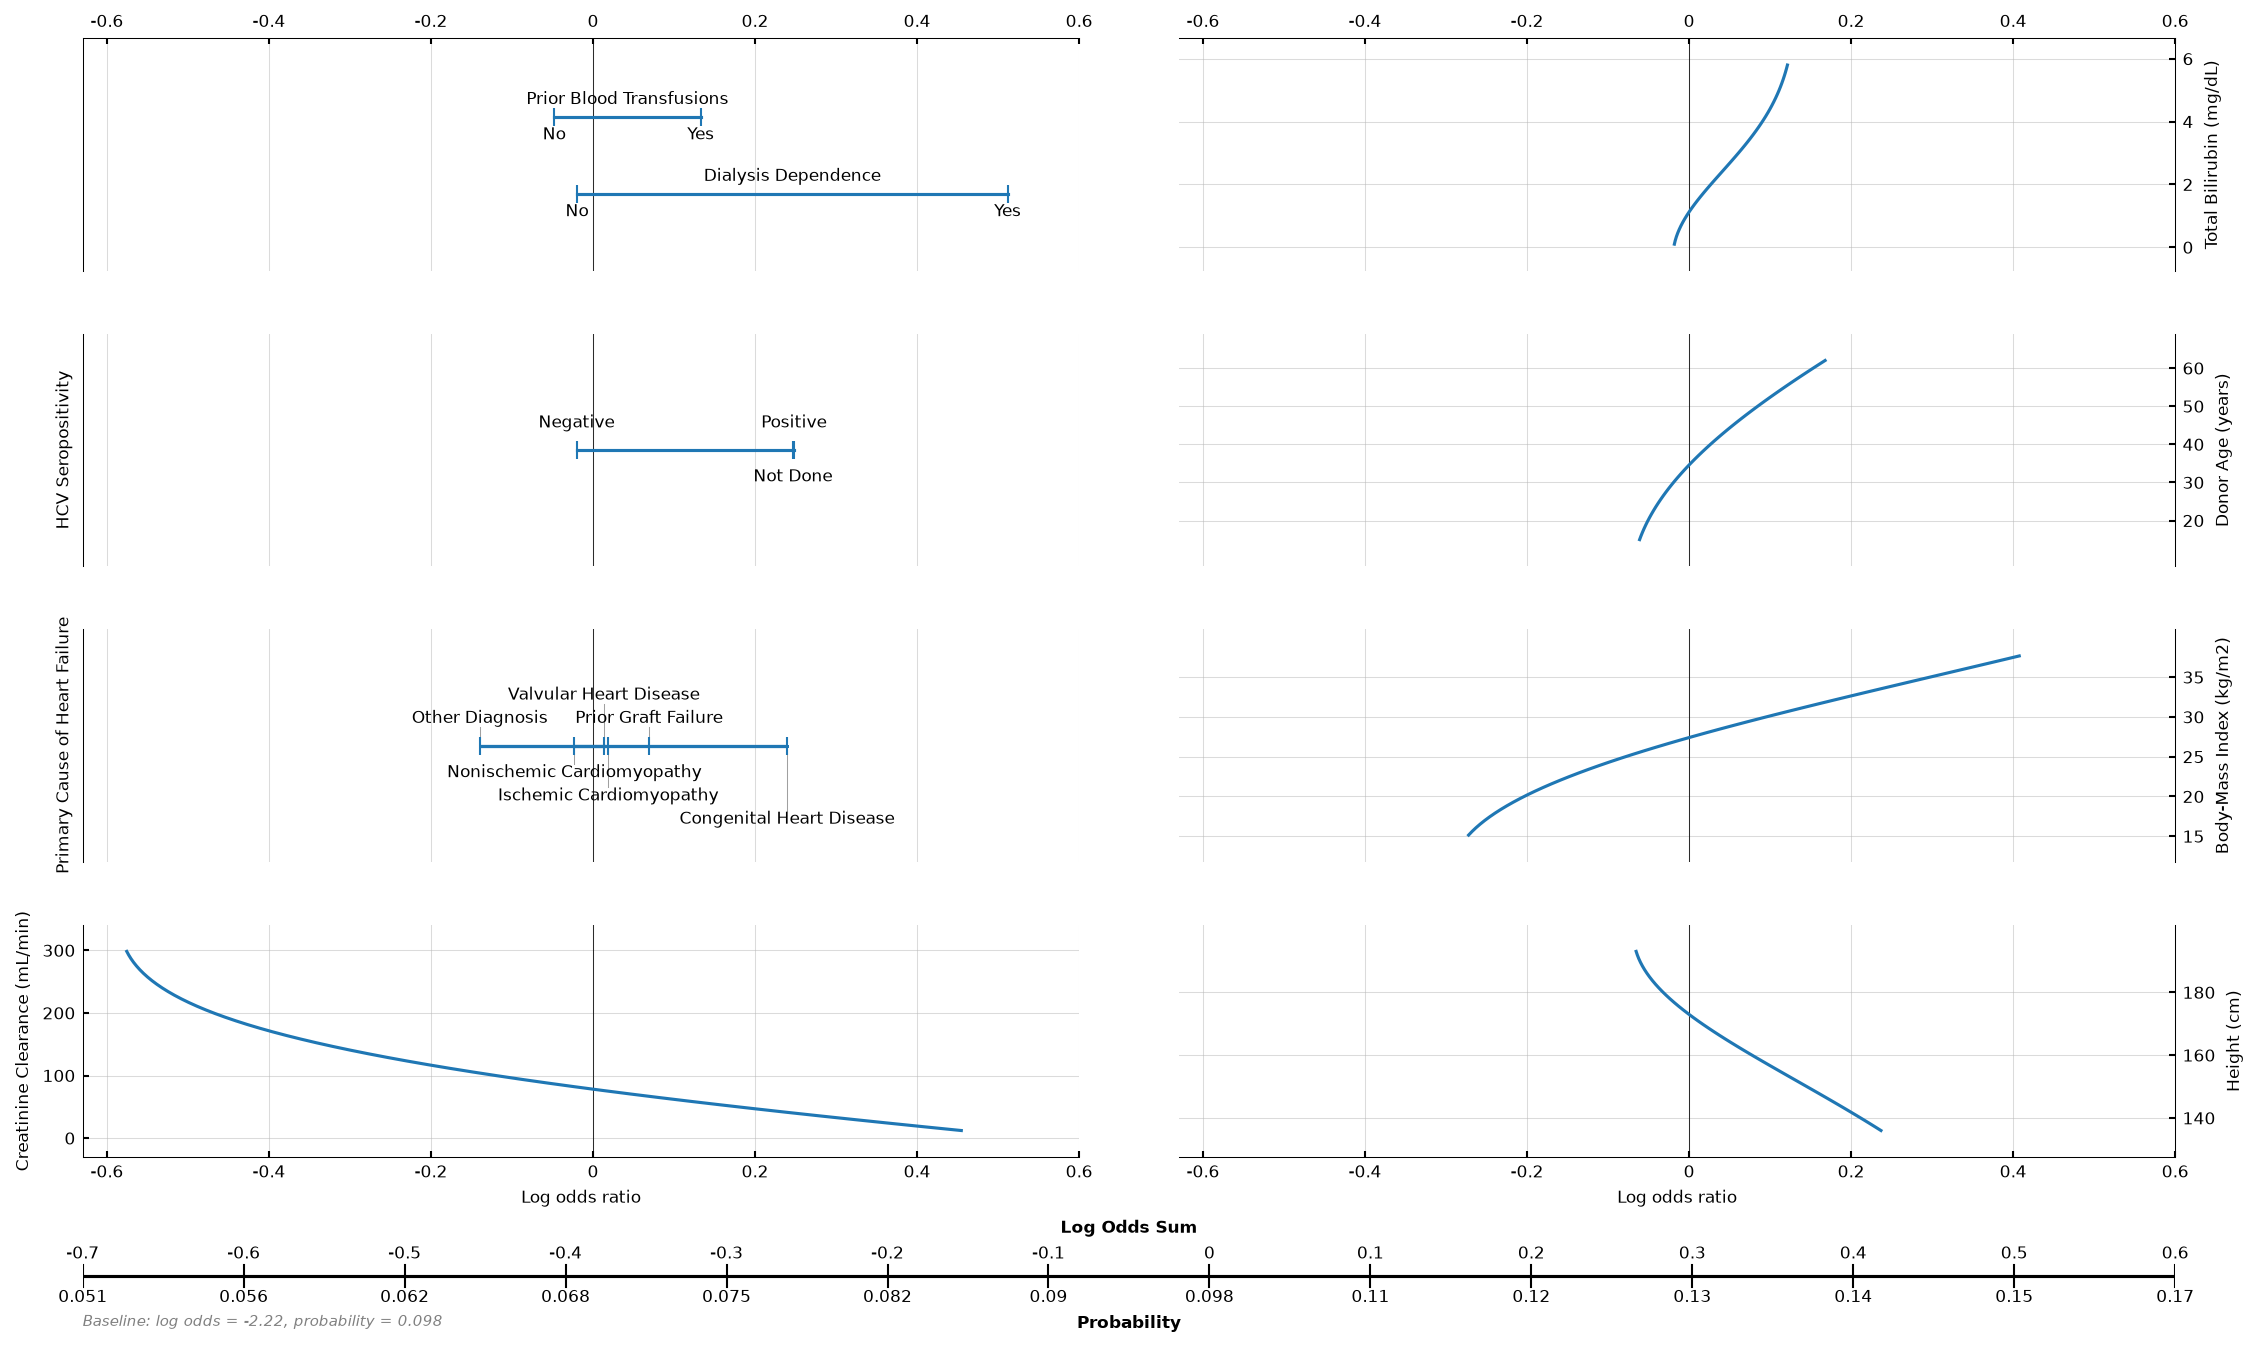

In [79]:
nomogram_params = {
    "n_steps": 50,
    "method": method,
    "x_train": X_tr,
    "device": device,
    "categorical_threshold": 15,
    "subtract_univariate": True,
    "return_fig": True,
    "use_odds_ratio": False,
    "save_json": False,
    "scaler": data.scaler,
    "onehot_group_manager": data.group_manager,
    "label_manager": label_manager,
    "feature_names": data.feature_names,
    "show_conversion_line": True,
    "legend_on_right": True,
}

result_blackbox = nomogram(lasso_results, x=X_tr, model=blackbox, **nomogram_params)

## 6. Phase II: the Partial Response Network

Phase I truncates the decomposition at second order, so its partial responses
are read from a source model whose behaviour also reflects third- and
higher-order interactions that the truncated form cannot represent. Phase II
re-estimates the selected terms in a model that admits nothing above second
order, which removes much of that residual influence and precludes overfitting
through unconstrained interaction complexity.

The effects selected in Phase I define the architecture of that model, a
**structurally constrained** network in which each selected effect gets its own
small subnetwork wired to *only* the 1-2 variables of that effect. A dropped
variable has no connections at all, and no subnetwork sees more than two
variables, so higher-order interactions cannot re-enter: they are excluded by
construction, not by regularization.

The mask below is that scaffold (rows = input variables, columns = hidden
units, 5 units per selected effect). Note what the PRN does *not* inherit:
Phase I's response shapes. It is trained from scratch against the outcome and
relearns every $\phi_k$ within the fixed wiring. The Phase I nomogram is
therefore the one that carries the shapes the source model learned. Phase II
trades some of that fidelity for a fit that cannot overfit through interaction
complexity, and has most to offer where Phase I has been sparsified hard enough
to cost discrimination.

Selected features: ['HCV Seropositivity', 'Primary Cause of Heart Failure', 'Dialysis Dependence', 'Prior Blood Transfusions', 'Creatinine Clearance (mL/min)', 'Total Bilirubin (mg/dL)', 'Donor Age (years)', 'Body-Mass Index (kg/m2)', 'Height (cm)']


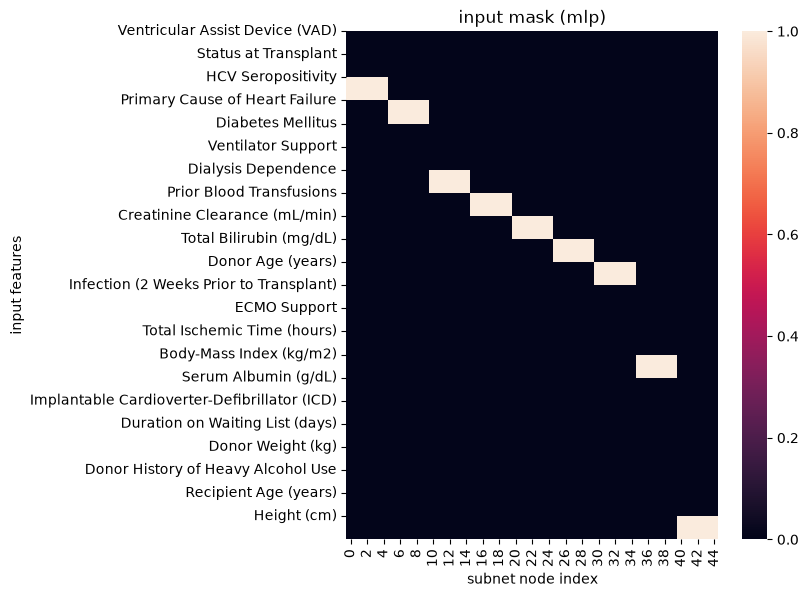

9 selected effects -> 45 hidden units


In [80]:
mask, n_effects = lasso_results.get_mask(subnet_nodes=5, verbose=True)
print(f"{n_effects} selected effects -> {mask.shape[1]} hidden units")

Epoch 0, Train Loss 0.699808, Test Loss 0.690945, Train AUROC 0.3957, Test AUROC 0.3865
Epoch 10, Train Loss 0.565944, Test Loss 0.565503, Train AUROC 0.3846, Test AUROC 0.3687
Epoch 20, Train Loss 0.460825, Test Loss 0.459927, Train AUROC 0.3839, Test AUROC 0.3645
Epoch 30, Train Loss 0.392664, Test Loss 0.390304, Train AUROC 0.3862, Test AUROC 0.3672
Epoch 40, Train Loss 0.359131, Test Loss 0.354781, Train AUROC 0.3899, Test AUROC 0.3728
Epoch 50, Train Loss 0.344683, Test Loss 0.338537, Train AUROC 0.3952, Test AUROC 0.3822
Epoch 60, Train Loss 0.337987, Test Loss 0.330689, Train AUROC 0.4041, Test AUROC 0.3977
Epoch 70, Train Loss 0.334352, Test Loss 0.326383, Train AUROC 0.4199, Test AUROC 0.4208
Epoch 80, Train Loss 0.331734, Test Loss 0.323537, Train AUROC 0.4411, Test AUROC 0.4552
Epoch 90, Train Loss 0.329534, Test Loss 0.321261, Train AUROC 0.4619, Test AUROC 0.4925
Epoch 100, Train Loss 0.327557, Test Loss 0.319317, Train AUROC 0.4850, Test AUROC 0.5245
Epoch 110, Train Loss

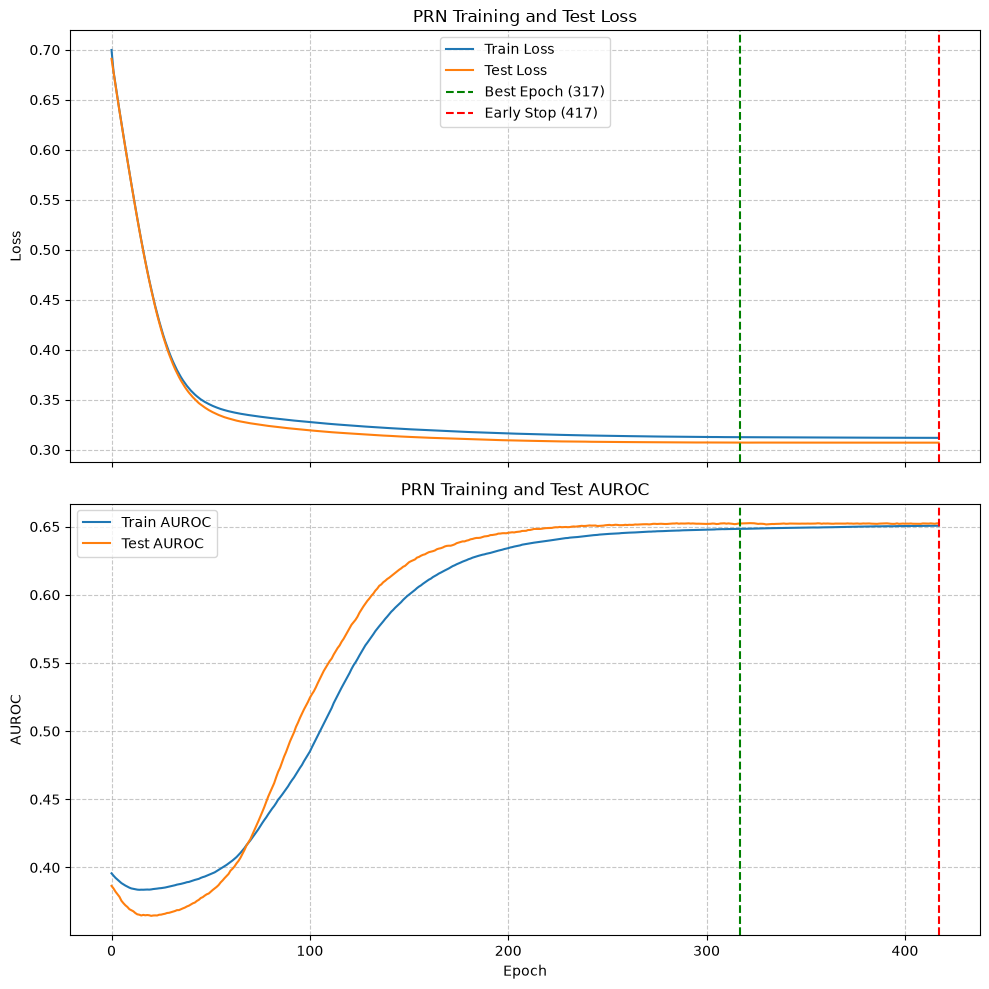

True

In [81]:
# build_prn_from_lasso rebuilds this mask internally (expanding categorical rows
# to the one-hot columns) and trains the masked network on the raw features
prn = build_prn_from_lasso(
    lasso_results,
    X_tr,
    data.y_train,
    X_te,
    data.y_test,
    group_manager=data.group_manager,
    feature_names=data.feature_names,
    subnet_nodes=5,
    lr=0.001,
    weight_decay=1e-5,
    tolerance=0.0001,
    patience=100,
    max_iter=4000,
    batch_size=256,
    device=str(device),
    seed=random_seed,
    plot_loss=False,
)
plot_training_history(get_training_history(prn), title_prefix="PRN")

C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: PRN - test data: Skipped confidence intervals for 1 bin(s) due to insufficient samples (threshold: 5). Bin indices: [3]. These bins had the following sample counts: [0.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:210: UserWarning: PRN - test data: 6 point(s) omitted: insufficient samples in probability range(s). Points omitted for probability range(s) [3]: no predictions in these ranges
  warnings.warn(



---- Model Performance Metrics PRN - test data ----
Threshold (prevalence) set to: 0.100
AUROC:		0.652 (95% CI: 0.619-0.702) (Area Under the Receiver Operating Characteristic curve)
Accuracy:	0.658 (Proportion of correct predictions)
Precision:	0.149 (Proportion of true positives among positive predictions, aka PPV)
Recall:		0.536 (Proportion of true positives among actual positives, aka sensitivity)
F1 Score:	0.233 (Harmonic mean of precision and recall)
--------------------------------------------


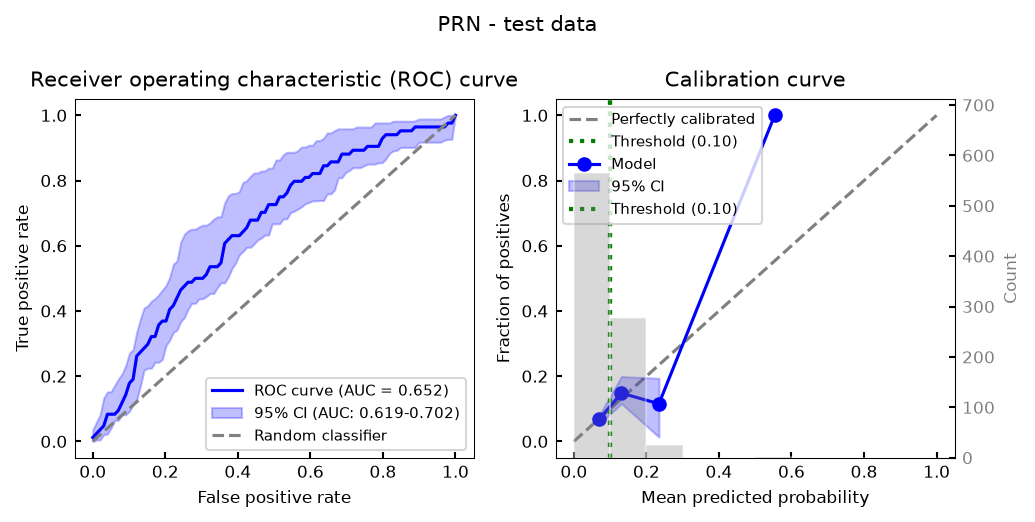

In [82]:
y_pred_test_prn = prn.predict_proba(X_te, device=device)
results_prn_test = evaluate_model_performance(
    data.y_test, y_pred_test_prn, data.y_train, title="PRN - test data"
)

## 7. Phase II: re-decompose and select again

The trained PRN is itself just a probabilistic classifier, so the same machinery
applies: decompose it into partial responses and run a second LASSO pass to
drop any terms the constrained re-fit made redundant. Effects that Phase I
eliminated stay eliminated: their re-decomposed responses are exactly flat,
because the PRN has no connections through them.

This walkthrough refines a Phase I selection that was already compact, so the
second pass has little left to remove and the term count barely moves. What
changes is the shape of the retained effects, which the side-by-side nomograms
below make visible. The case Phase II is aimed at is the harder one: a Phase I
selection sparsified far enough to lose discrimination, where re-estimating the
surviving terms under the structural constraint can recover it.

In [83]:
pr_params_prn = {**pr_params, "batch_size": 32}
pr_train_prn = partial_responses(X_tr, prn, **pr_params_prn)
pr_test_prn = partial_responses(X_te, prn, **pr_params_prn)
cleanup_gpu_memory(device)

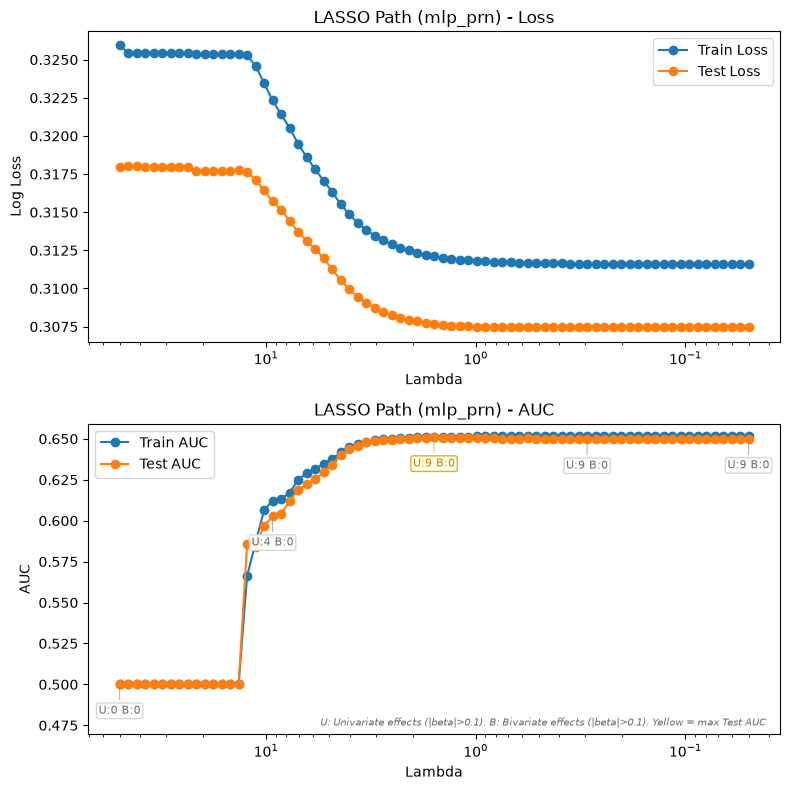

                     LASSO Regression Results (mlp_prn)                      
╭───────┬─────────┬────────┬────────┬────────┬────────┬──────────┬──────────╮
│       │         │  Train │   Test │  Train │   Test │    Univ. │     Biv. │
│ Index │  Lambda │    AUC │    AUC │   Loss │   Loss │ beta>0.1 │ beta>0.1 │
├───────┼─────────┼────────┼────────┼────────┼────────┼──────────┼──────────┤
│     0 │      50 │ 0.5000 │ 0.5000 │ 0.3259 │ 0.3179 │        0 │        0 │
│     1 │   45.54 │ 0.5000 │ 0.5000 │ 0.3255 │ 0.3180 │        0 │        0 │
│     2 │   41.48 │ 0.5000 │ 0.5000 │ 0.3255 │ 0.3180 │        0 │        0 │
│     3 │   37.79 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     4 │   34.42 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     5 │   31.35 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     6 │   28.56 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     7 │   26.01 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     8 │   23.69 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3180 │        0 │        0 │
│     9 │   21.58 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    10 │   19.66 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    11 │   17.91 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    12 │   16.31 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    13 │   14.86 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3177 │        0 │        0 │
│    14 │   13.53 │ 0.5000 │ 0.5000 │ 0.3254 │ 0.3178 │        0 │        0 │
│    15 │   12.33 │ 0.5662 │ 0.5859 │ 0.3253 │ 0.3177 │        0 │        0 │
│    16 │   11.23 │ 0.5866 │ 0.5842 │ 0.3246 │ 0.3171 │        2 │        0 │
│    17 │   10.23 │ 0.6065 │ 0.5969 │ 0.3235 │ 0.3164 │        2 │        0 │
│    18 │   9.316 │ 0.6122 │ 0.6027 │ 0.3223 │ 0.3157 │        4 │        0 │
│    19 │   8.486 │ 0.6133 │ 0.6039 │ 0.3214 │ 0.3152 │        4 │        0 │
│    20 │    7.73 │ 0.6169 │ 0.6121 │ 0.3205 │ 0.3144 │        4 │        0 │
│    21 │   7.041 │ 0.6251 │ 0.6187 │ 0.3195 │ 0.3137 │        6 │        0 │
│    22 │   6.413 │ 0.6290 │ 0.6222 │ 0.3186 │ 0.3131 │        6 │        0 │
│    23 │   5.842 │ 0.6318 │ 0.6253 │ 0.3178 │ 0.3126 │        6 │        0 │
│    24 │   5.321 │ 0.6346 │ 0.6297 │ 0.3171 │ 0.3120 │        7 │        0 │
│    25 │   4.847 │ 0.6375 │ 0.6341 │ 0.3163 │ 0.3113 │        8 │        0 │
│    26 │   4.415 │ 0.6418 │ 0.6401 │ 0.3155 │ 0.3105 │        9 │        0 │
│    27 │   4.021 │ 0.6451 │ 0.6437 │ 0.3149 │ 0.3099 │        9 │        0 │
│    28 │   3.663 │ 0.6468 │ 0.6459 │ 0.3143 │ 0.3095 │        9 │        0 │
│    29 │   3.337 │ 0.6482 │ 0.6478 │ 0.3138 │ 0.3091 │        9 │        0 │
│    30 │   3.039 │ 0.6491 │ 0.6485 │ 0.3135 │ 0.3087 │        9 │        0 │
│    31 │   2.768 │ 0.6497 │ 0.6491 │ 0.3132 │ 0.3085 │        9 │        0 │
│    32 │   2.522 │ 0.6501 │ 0.6495 │ 0.3129 │ 0.3083 │        9 │        0 │
│    33 │   2.297 │ 0.6505 │ 0.6500 │ 0.3127 │ 0.3081 │        9 │        0 │
│    34 │   2.092 │ 0.6507 │ 0.6501 │ 0.3125 │ 0.3079 │        9 │        0 │
│    35 │   1.906 │ 0.6510 │ 0.6502 │ 0.3123 │ 0.3078 │        9 │        0 │
│    36 │   1.736 │ 0.6510 │ 0.6508 │ 0.3122 │ 0.3077 │        9 │        0 │
│  * 37 │   1.581 │ 0.6511 │ 0.6509 │ 0.3121 │ 0.3077 │        9 │        0 │
│    38 │    1.44 │ 0.6511 │ 0.6506 │ 0.3120 │ 0.3076 │        9 │        0 │
│    39 │   1.312 │ 0.6512 │ 0.6506 │ 0.3120 │ 0.3076 │        9 │        0 │
│    40 │   1.195 │ 0.6512 │ 0.6505 │ 0.3119 │ 0.3075 │        9 │        0 │
│    41 │   1.088 │ 0.6514 │ 0.6505 │ 0.3118 │ 0.3075 │        9 │        0 │
│    42 │  0.9914 │ 0.6515 │ 0.6504 │ 0.3118 │ 0.3075 │        9 │        0 │
│    43 │  0.9031 │ 0.6515 │ 0.6503 │ 0.3118 │ 0.3075 │        9 │        0 │
│    44 │  0.8226 │ 0.6516 │ 0.6502 │ 0.3117 │ 0.3075 │        9 │        0 │
│    45 │  0.7493 │ 0.6515 │ 0.6500 │ 0.3117 │ 0.3075 │        9 │        0 │
│    46 │  0.6825 │ 0.

Logging is configured but no file handlers were found.


In [84]:
lasso_prn = LassoRegression(
    nlambda=75,
    min_lambda=0.05,
    max_lambda=50,
    max_features=60,
    max_iter=2000,
    max_workers=get_num_cpu_workers(),
    seed=random_seed,
    base_model_name="mlp_prn",
)
lasso_results_prn, _ = lasso_prn.fit(
    pr_train_prn, pr_test_prn, data.y_train, data.y_test, feature_names=lasso_feature_names
)

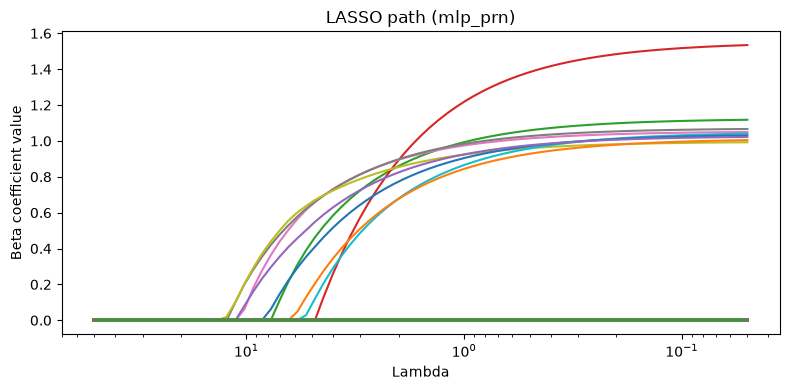

╭──────────────────────────────────────────────── Model Selection ────────────────────────────────────────────────╮
│ Lambda Selection Strategy: Target Ratio 99.8% of Max AUC                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

         Selected Lambda Results         
╭──────────────────────────────┬────────╮
│                       Metric │ Value  │
├──────────────────────────────┼────────┤
│                 Lambda Index │ 33     │
│                 Lambda Value │ 2.2968 │
│                     Test AUC │ 0.6500 │
│                    Train AUC │ 0.6505 │
│               Total Features │ 9      │
│          Univariate Features │ 9      │
│           Bivariate Features │ 0      │
├──────────────────────────────┼────────┤
│         Maximum Possible AUC │ 0.6509 │
│     Maximum AUC Lambda Index │ 37     │
│       Percent of Maximum AUC │ 99.9%  │
├──────────────────────────────┼────────┤
│       Max AUC Model Features │ 9      │
│            Feature Reduction │ 0.0%   │
│ Univariate Feature Reduction │ 0.0%   │
│  Bivariate Feature Reduction │ N/A    │
╰──────────────────────────────┴────────╯

                   Selected Features (|beta| > 0.1)                   
╭────────────────────┬────────────────────────────────┬──────────────╮
│ Coefficient (beta) │ Feature                        │     Type     │
├────────────────────┼────────────────────────────────┼──────────────┤
│             0.8727 │ Prior Blood Transfusions       │  Univariate  │
│             0.8712 │ Dialysis Dependence            │  Univariate  │
│             0.8345 │ Creatinine Clearance (mL/min)  │  Univariate  │
│             0.8201 │ HCV Seropositivity             │  Univariate  │
│             0.7980 │ Primary Cause of Heart Failure │  Univariate  │
│             0.7953 │ Body-Mass Index (kg/m2)        │  Univariate  │
│             0.7350 │ Donor Age (years)              │  Univariate  │
│             0.6277 │ Height (cm)                    │  Univariate  │
│             0.6225 │ Total Bilirubin (mg/dL)        │  Univariate  │
├────────────────────┼────────────────────────────────┼──────────────┤
│           Total: 9 │ Univariate: 9                  │ Bivariate: 0 │
╰────────────────────┴────────────────────────────────┴──────────────╯

Logistic regression model for Lambda index 33 (2.297) selected. |beta| > 0.1 kept.
PRN nomogram: 9 terms (9 main effects, 0 interactions)


In [85]:
lasso_results_prn.plot_lambda_path()
lasso_results_prn.select_lambda_max_test_auc(target_ratio=0.998)

prn_nomogram = lasso_results_prn.get_selected_model()
counts_prn = get_term_counts(lasso_results_prn)
print(
    f"PRN nomogram: {counts_prn['n_total']} terms "
    f"({counts_prn['n_univ']} main effects, {counts_prn['n_biv']} interactions)"
)

Logistic regression model for Lambda index 33 (2.297) selected. |beta| > 0.1 kept.


C:\Users\user\PRiSM\prism\plotting\renderer.py:1182: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


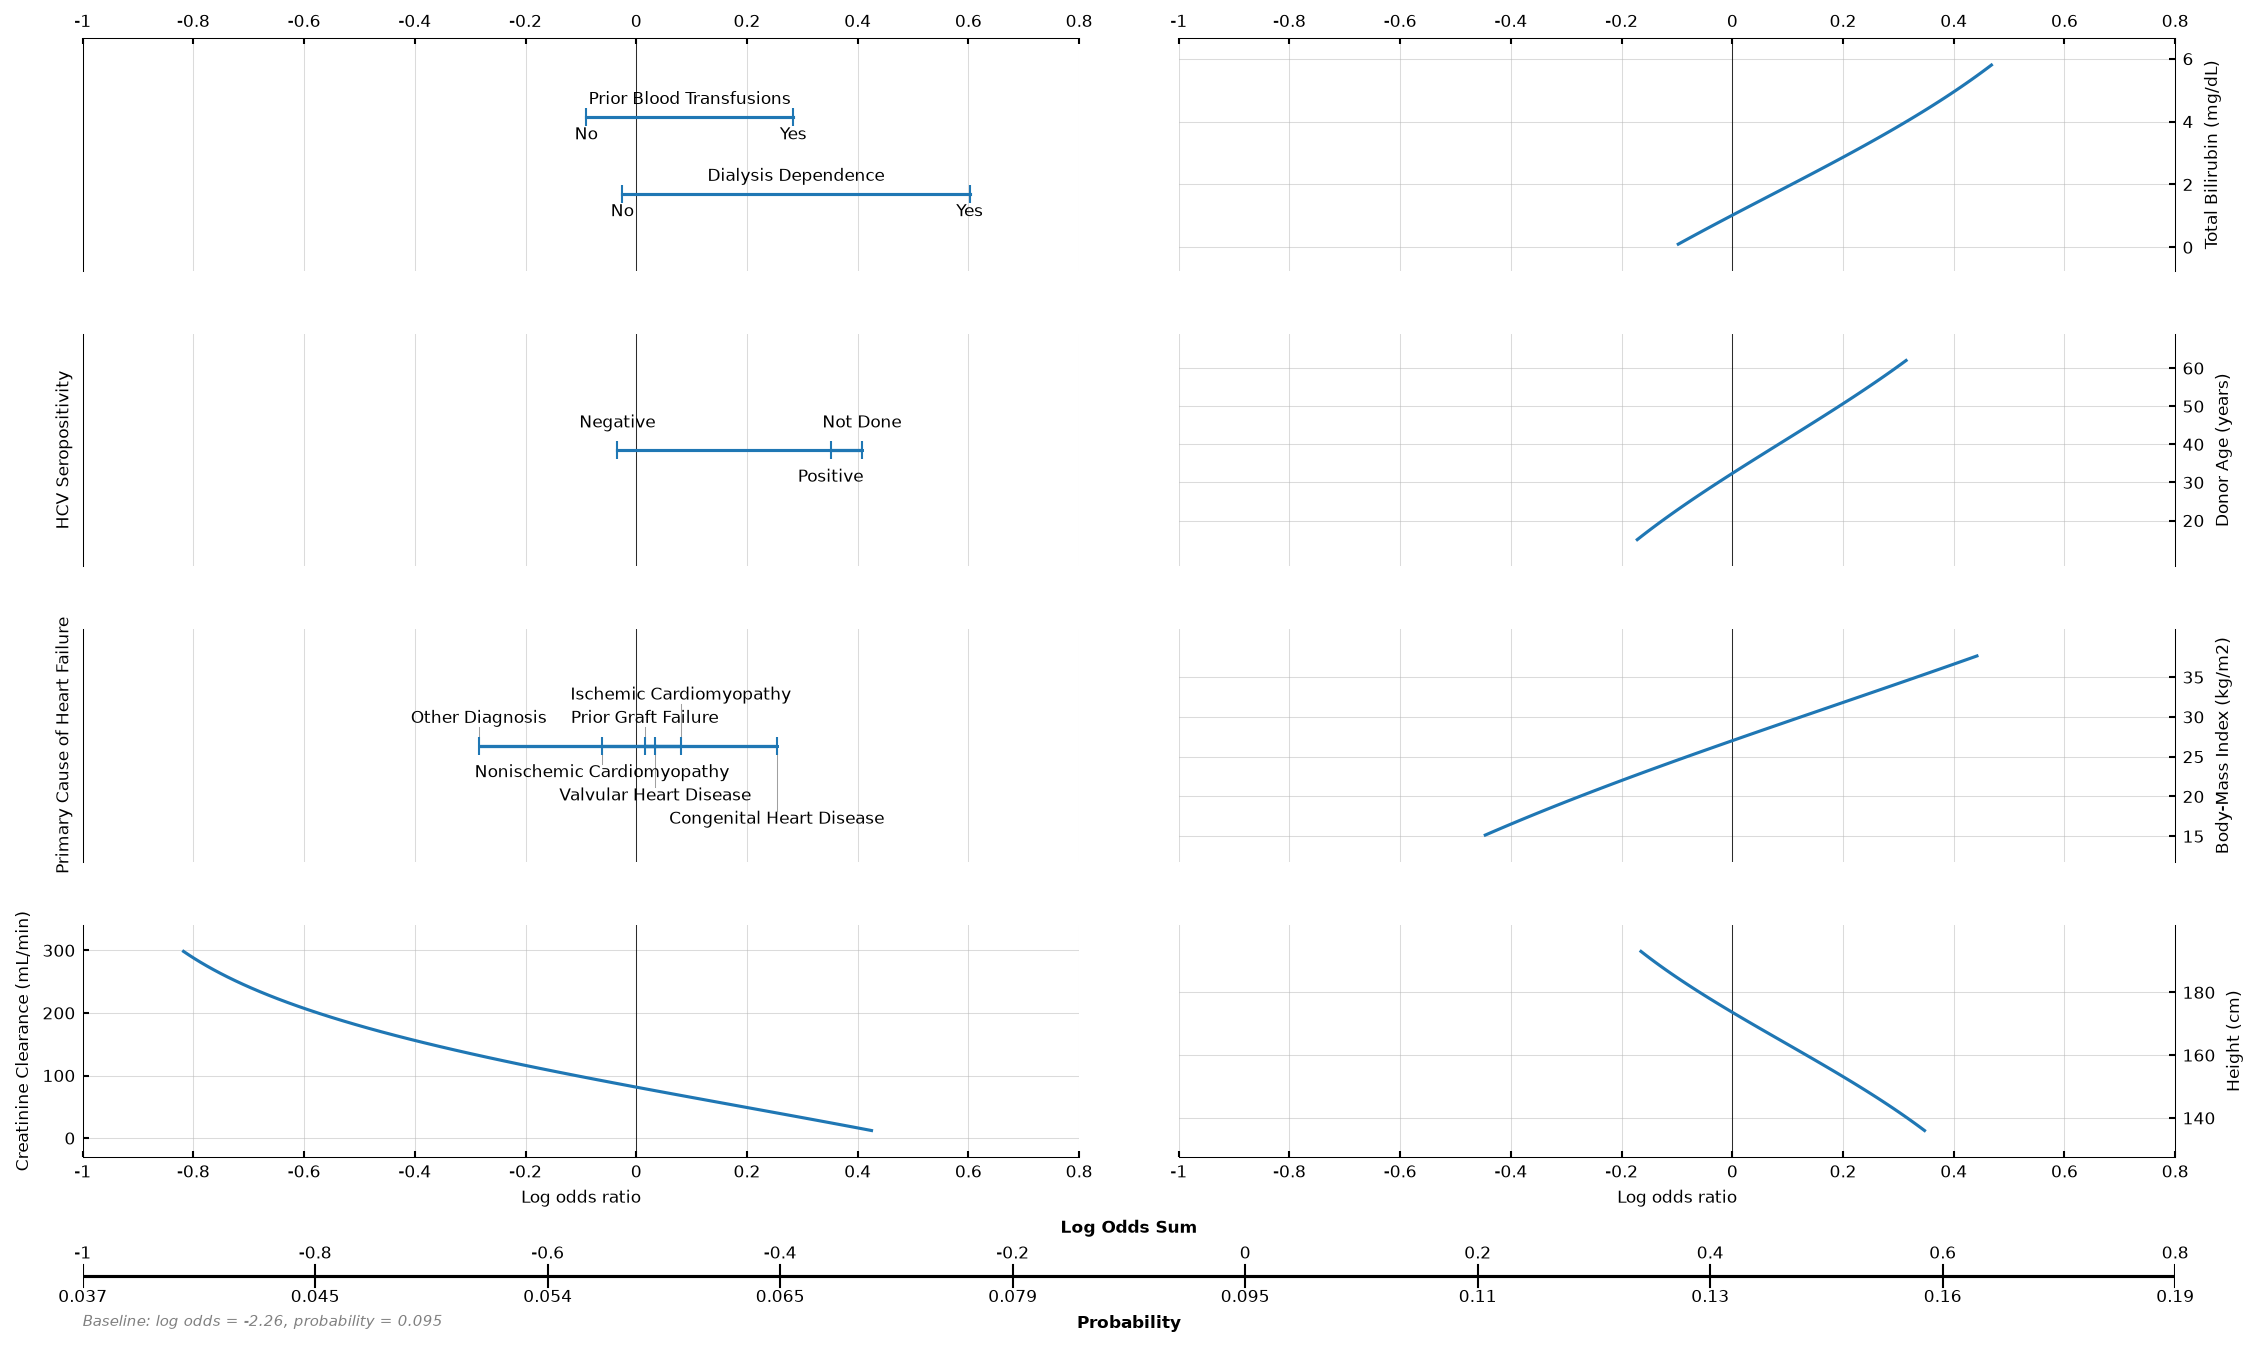

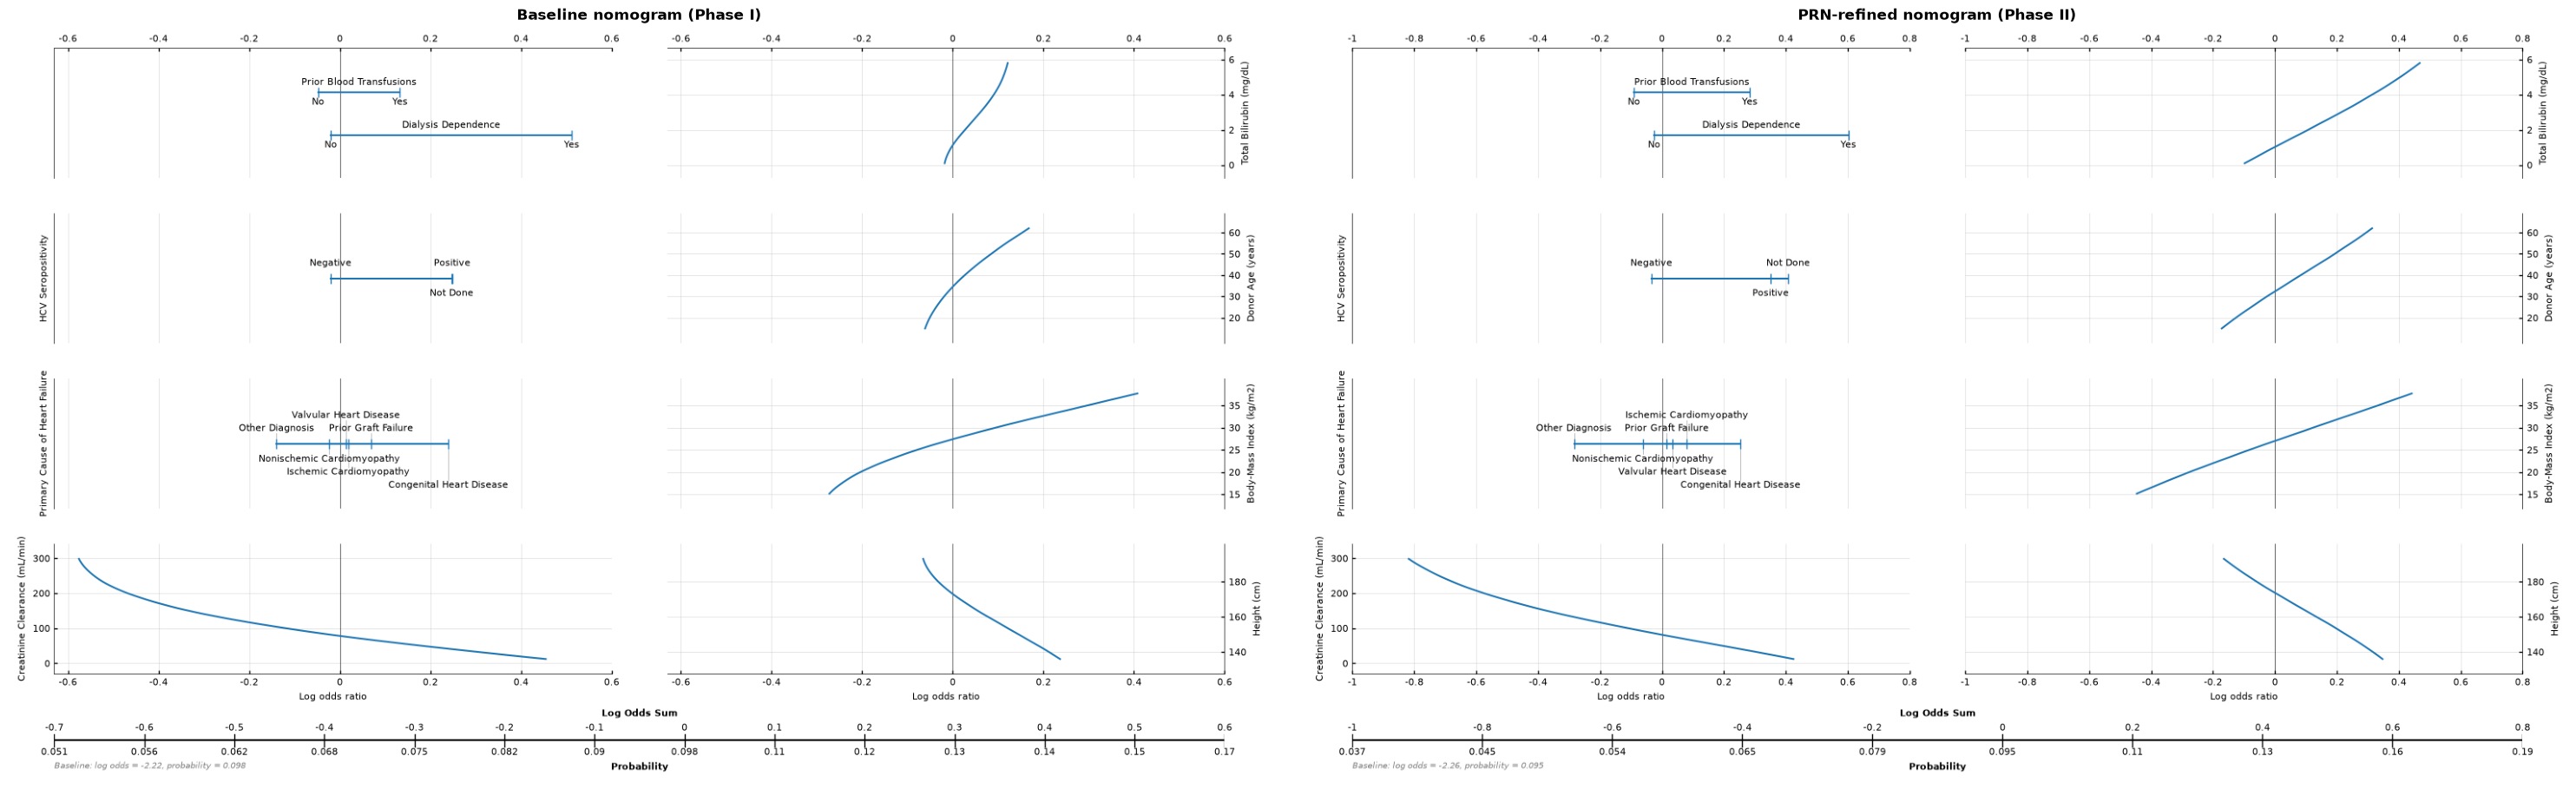

In [86]:
result_prn = nomogram(lasso_results_prn, x=X_tr, model=prn, **nomogram_params)

_ = display_nomograms_side_by_side(
    nomograms=[
        (result_blackbox.fig_main, result_blackbox.fig_bivariate),
        (result_prn.fig_main, result_prn.fig_bivariate),
    ],
    titles=["Baseline nomogram (Phase I)", "PRN-refined nomogram (Phase II)"],
)

## 8. Validation: four predictors, one held-out split

The validation split has played no role so far: not in training, not in
selection. We now score all four predictors on it:

1. the original **black box**,
2. the **baseline nomogram** (Phase I terms + weights),
3. the **PRN** (the constrained network itself), and
4. the **PRN-refined nomogram** (Phase II terms + weights).

Both nomograms are usable end products, and choosing between them is a
deployment decision. Take the baseline nomogram where auditable fidelity to the
source model matters most, since it carries the shapes the black box learned.
Take the PRN-refined nomogram where parsimony matters most and the structural
constraint has bought something.

The two figures below put each nomogram against the black box it was derived
from. The key thing to look for is that the nomograms give up little
discrimination relative to that black box, while being fully readable. Compare
magnitudes rather than third decimals: the confidence intervals here are wide
next to the differences between models, so nothing in this table ranks them.

C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: Black box (MLP): Skipped confidence intervals for 3 bin(s) due to insufficient samples (threshold: 5). Bin indices: [4 5 6]. These bins had the following sample counts: [1. 4. 1.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:570: UserWarning: Black box (MLP): 3 point(s) omitted: insufficient samples in probability range(s)
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: Baseline nomogram: Skipped confidence intervals for 1 bin(s) due to insufficient samples (threshold: 5). Bin indices: [3]. These bins had the following sample counts: [1.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:570: UserWarning: Baseline nomogram: 6 point(s) omitted: insufficient samples in probability range(s)
  warnings.warn(



-------- Model Performance Comparison --------
Threshold (prevalence) set to: 0.100

Black box (MLP):
AUROC:		0.650 (95% CI: 0.599-0.699)
Accuracy:	0.674
Precision:	0.152
Recall:		0.588
F1 Score:	0.241

Baseline nomogram:
AUROC:		0.659 (95% CI: 0.602-0.695)
Accuracy:	0.657
Precision:	0.149
Recall:		0.612
F1 Score:	0.239
------------------------------------------------


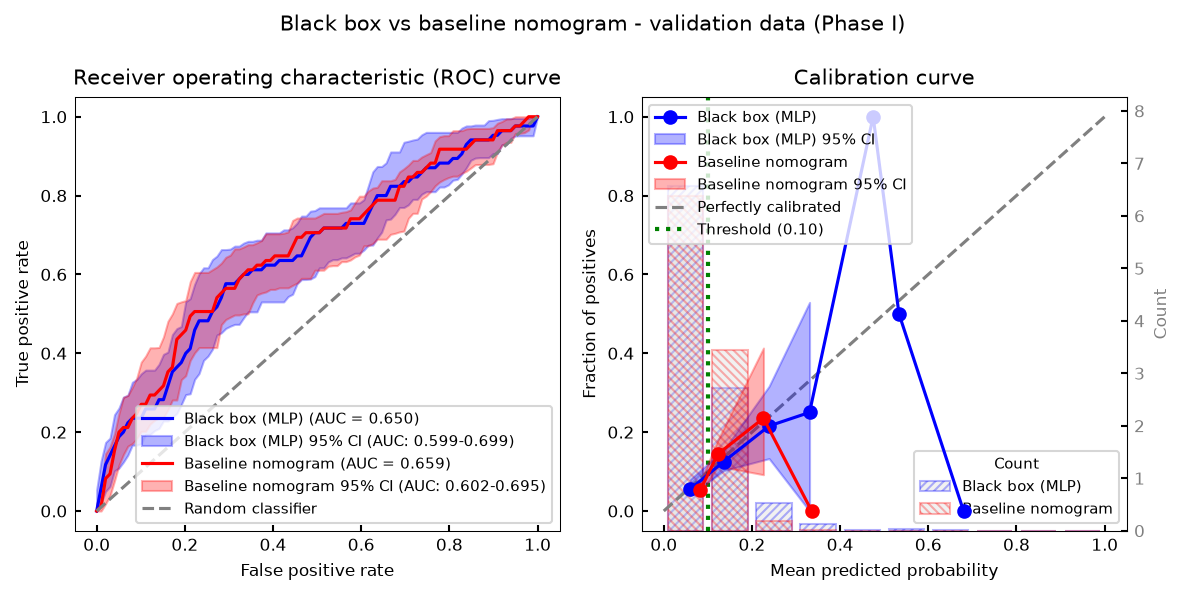

C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: Black box (MLP): Skipped confidence intervals for 3 bin(s) due to insufficient samples (threshold: 5). Bin indices: [4 5 6]. These bins had the following sample counts: [1. 4. 1.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:570: UserWarning: Black box (MLP): 3 point(s) omitted: insufficient samples in probability range(s)
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: PRN-refined nomogram: Skipped confidence intervals for 2 bin(s) due to insufficient samples (threshold: 5). Bin indices: [3 4]. These bins had the following sample counts: [3. 1.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:570: UserWarning: PRN-refined nomogram: 5 point(s) omitted: insufficient samples in probability range(s)
  warnings.warn(



-------- Model Performance Comparison --------
Threshold (prevalence) set to: 0.100

Black box (MLP):
AUROC:		0.650 (95% CI: 0.599-0.699)
Accuracy:	0.674
Precision:	0.152
Recall:		0.588
F1 Score:	0.241

PRN-refined nomogram:
AUROC:		0.665 (95% CI: 0.602-0.702)
Accuracy:	0.686
Precision:	0.153
Recall:		0.565
F1 Score:	0.241
------------------------------------------------


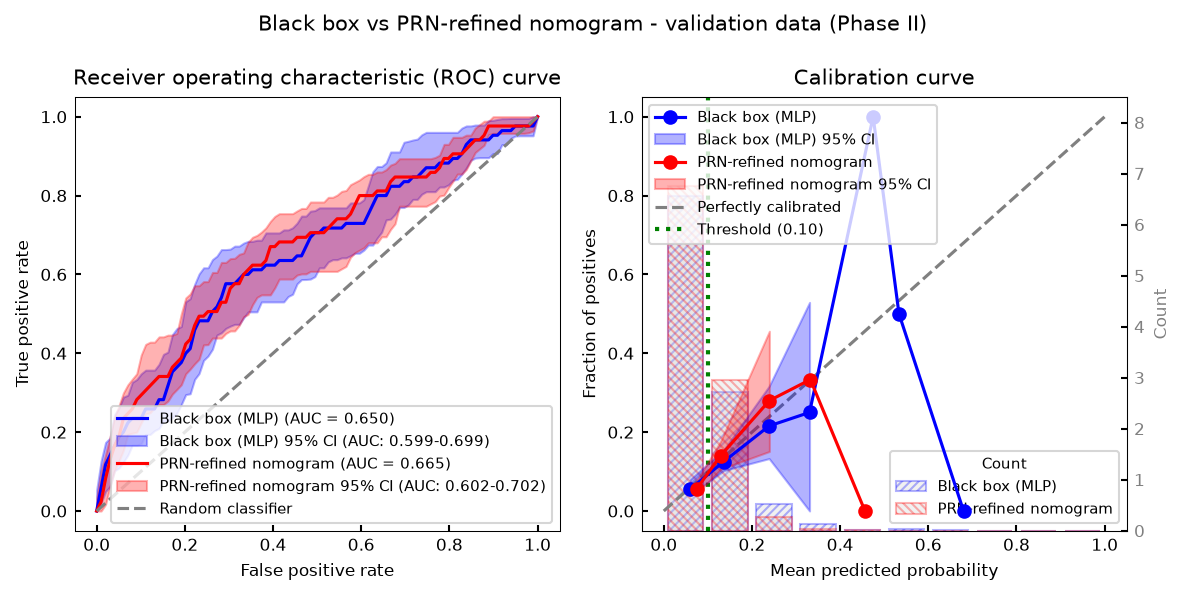

In [87]:
pr_val = partial_responses(X_va, blackbox, **pr_params)
pr_val_prn = partial_responses(X_va, prn, **pr_params_prn)
cleanup_gpu_memory(device)

y_pred_val_blackbox = blackbox.predict_proba(X_va, device=device)
y_pred_val_bb_nomogram = blackbox_nomogram.predict_proba(pr_val)[:, 1]
y_pred_val_prn = prn.predict_proba(X_va, device=device)
y_pred_val_prn_nomogram = prn_nomogram.predict_proba(pr_val_prn)[:, 1]

comparison_phase1 = compare_model_performance(
    data.y_val,
    y_pred_val_blackbox,
    y_pred_val_bb_nomogram,
    y_train=data.y_train,
    model_names=("Black box (MLP)", "Baseline nomogram"),
    title="Black box vs baseline nomogram - validation data (Phase I)",
    random_seed=random_seed,
)

comparison_phase2 = compare_model_performance(
    data.y_val,
    y_pred_val_blackbox,
    y_pred_val_prn_nomogram,
    y_train=data.y_train,
    model_names=("Black box (MLP)", "PRN-refined nomogram"),
    title="Black box vs PRN-refined nomogram - validation data (Phase II)",
    random_seed=random_seed,
)

In [88]:
# The two comparisons already carry AUROC and its CI for three of the four
# predictors; only the PRN network itself needs a separate scoring pass.
results_val_prn = evaluate_model_performance(
    data.y_val, y_pred_val_prn, data.y_train, show_results=False, random_seed=random_seed
)

val_rows = [
    ("Black box (MLP)", comparison_phase1["Black box (MLP)"], None),
    ("Baseline nomogram", comparison_phase1["Baseline nomogram"], counts),
    ("PRN", results_val_prn, None),
    ("PRN-refined nomogram", comparison_phase2["PRN-refined nomogram"], counts_prn),
]

summary = pd.DataFrame(
    [
        {
            "Model": name,
            "Nomogram terms": term_counts["n_total"] if term_counts else "-",
            "Validation AUROC": f"{res['auroc']:.3f}",
            "95% CI": f"{res['auroc_ci'][0]:.3f}-{res['auroc_ci'][1]:.3f}",
        }
        for name, res, term_counts in val_rows
    ]
).set_index("Model")
summary

C:\Users\user\PRiSM\prism\metrics.py:841: UserWarning: Model: Skipped confidence intervals for 2 bin(s) due to insufficient samples (threshold: 5). Bin indices: [4 5]. These bins had the following sample counts: [1. 1.].
  warnings.warn(
C:\Users\user\PRiSM\prism\metrics.py:210: UserWarning: Model: 4 point(s) omitted: insufficient samples in probability range(s)
  warnings.warn(


,Nomogram terms,Validation AUROC,95% CI
Model,,,
Black box (MLP),-,0.650,0.599-0.699
Baseline nomogram,9,0.659,0.602-0.695
PRN,-,0.668,0.609-0.705
PRN-refined nomogram,9,0.665,0.602-0.702


## Where to go from here

Both nomograms above are additive, hand-computable predictors that can stand in
for the MLP: the baseline one from Phase I, the PRN-refined one from Phase II.
For real projects you will
want the config-driven pipeline, which wraps these same steps with caching,
artifact tracking, JSON nomogram export, and batch execution:

- **Config-driven notebooks:** set `PRISM_CONFIG` in `.env` and run
  `preprocessing.ipynb` -> `modelling/train_*.ipynb` -> `prism_analysis.ipynb`.
- **CLI:** `prism run htx_example` runs the whole pipeline for a YAML config in
  `example_notebooks/config/`; see `example_config.yaml` for every option.
- **Your own data:** drop a CSV in `data/raw/`, write a small YAML config (or
  call `prism.data.prepare_dataset` directly, as this notebook effectively did),
  and choose `lebesgue` for the more accurate decomposition or `dirac` for
  quick iteration.